# Supervised Learning - Classification Models

##### **NOTE:** Training the models with default values 

In [1]:
import pandas as pd

df = pd.read_csv("D:\\Heart_Disease_Project\\data\\heart_disease_feature_selected.csv")
#df = pd.read_csv("D:\\Heart_Disease_Project\\data\\heart_diseasePCA.csv")
#df = pd.read_csv("D:\\Heart_Disease_Project\\data\\heart_disease.csv")

X = df.drop(columns=['target'])  
y = df['target']  

# Initialize a DataFrame to hold the metrics for final comparison.
comparison_df = pd.DataFrame(columns=['accuracy', 'precision', 'recall', 'f1_score'])

print(X.shape)
print(y.shape)

(303, 9)
(303,)


## 1. Split the dataset into training (80%) and testing (20%) sets. 

In [14]:
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")


Shape of X_train: (242, 9)
Shape of X_test: (61, 9)
Shape of y_train: (242,)
Shape of y_test: (61,)


## 2. Train the following models: 

### ○ Logistic Regression 

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

LR_model = LogisticRegression()
LR_model.fit(X_train,y_train)


y_pred_LR = LR_model.predict(X_test)

report_LR = classification_report(y_test, y_pred_LR, output_dict=True)
accuracy_LR = report_LR['accuracy']
precision_LR = report_LR['weighted avg']['precision']
recall_LR = report_LR['weighted avg']['recall']
f1_score_LR = report_LR['weighted avg']['f1-score']

print(f"\nModel Accuracy: {accuracy_LR * 100:.2f}%")
print("\nClassification Report:")
print(pd.DataFrame(report_LR))

comparison_df.loc["Logistic Regression"] = [accuracy_LR, precision_LR, recall_LR, f1_score_LR]

# data with feature selection that has 9 features has accuracy of 88.52%
# data with PCA which has 12 Principle component has accuracy of 86.89%
# Original data with 18 features has accuracy of 85.25$


Model Accuracy: 88.52%

Classification Report:
                   0          1  accuracy  macro avg  weighted avg
precision   0.892857   0.878788  0.885246   0.885823      0.885477
recall      0.862069   0.906250  0.885246   0.884159      0.885246
f1-score    0.877193   0.892308  0.885246   0.884750      0.885122
support    29.000000  32.000000  0.885246  61.000000     61.000000


#### - **Logistic Regression** model achieved a high accuracy of **88.52%** on the test set. The well-balanced precision and recall scores across both classes demonstrate that the model generalizes effectively to unseen data without showing a significant performance bias towards either class.
#### - It is also obvious that using feature selection has better results than using PCA or the original data

### ○ Decision Tree 

In [4]:
from sklearn.tree import DecisionTreeClassifier

DT_model = DecisionTreeClassifier(random_state=42)

DT_model.fit(X_train,y_train)
y_pred_DT = DT_model.predict(X_test)



report_DT = classification_report(y_test, y_pred_DT, output_dict=True)
accuracy_DT = report_DT['accuracy']
precision_DT = report_DT['weighted avg']['precision']
recall_DT = report_DT['weighted avg']['recall']
f1_score_DT = report_DT['weighted avg']['f1-score']

print(f"\nModel Accuracy: {accuracy_DT * 100:.2f}%")
print("\nClassification Report:")
print(pd.DataFrame(report_DT))

comparison_df.loc["Decision Tree"] = [accuracy_DT, precision_DT, recall_DT, f1_score_DT]

# data with feature selection that has 9 features has accuracy of 80.33%
# data with PCA which has 12 Principle component has accuracy of 70.49%
# Original data with 18 features has accuracy of 68.85$


Model Accuracy: 80.33%

Classification Report:
                   0          1  accuracy  macro avg  weighted avg
precision   0.757576   0.857143  0.803279   0.807359      0.809808
recall      0.862069   0.750000  0.803279   0.806034      0.803279
f1-score    0.806452   0.800000  0.803279   0.803226      0.803067
support    29.000000  32.000000  0.803279  61.000000     61.000000


#### - **Decision Tree** has accuracy of **80.33%** with better results for class 1 as its more aggressive in predicting class 1 (higher recall lower precision) and more cautious with predicting class 0 (higher precision and lower recall)
#### - It is also obvious that using feature selection has better results than using PCA or the original data **using model's default values**

### ○ Random Forest 

In [5]:
from sklearn.ensemble import RandomForestClassifier


RF_model = RandomForestClassifier(random_state=42)

RF_model.fit(X_train,y_train)
y_pred_RF = RF_model.predict(X_test)



report_RF = classification_report(y_test, y_pred_RF, output_dict=True)
accuracy_RF = report_RF['accuracy']
precision_RF = report_RF['weighted avg']['precision']
recall_RF = report_RF['weighted avg']['recall']
f1_score_RF = report_RF['weighted avg']['f1-score']

print(f"\nModel Accuracy: {accuracy_RF * 100:.2f}%")
print("\nClassification Report:")
print(pd.DataFrame(report_RF))

comparison_df.loc["Random Forest"] = [accuracy_RF, precision_RF, recall_RF, f1_score_RF]

# data with feature selection that has 9 features has accuracy of 83.61%
# data with PCA which has 12 Principle component has accuracy of 83.61%
# Original data with 18 features has accuracy of 86.89$


Model Accuracy: 83.61%

Classification Report:
                   0          1  accuracy  macro avg  weighted avg
precision   0.787879   0.892857  0.836066   0.840368      0.842949
recall      0.896552   0.781250  0.836066   0.838901      0.836066
f1-score    0.838710   0.833333  0.836066   0.836022      0.835889
support    29.000000  32.000000  0.836066  61.000000     61.000000


#### - **Random Forest** has accuracy of **83.61%** using feature selection and it is not well balanced between precision and recall of the two classes but the F1 is so close between them 
#### - This model finds mostly all class 0 as it aggresively predicts it (higher recall and lower precision) while it has higher precision in class 0 which means it is more precise and more cautious while predicting class 1 (higher precision and lower recall)
#### - For the first time the original data has better results than using feature selection and also PCA method has identical accuracy with feature selection which was always a little bit lower than it which is expected as Random Forest handles many features well

#### Why Random Forest Handles Many Features Well

A **Random Forest** works well with many features because it builds hundreds of decision trees and combines their outputs. It's robust to noise due to two key mechanisms:

* **Feature Randomness**: Each tree is built using only a random subset of the total features, preventing any single feature from dominating.
* **Ensemble Voting**: Errors or biases from a few individual trees are outvoted and corrected by the majority, making the final prediction more accurate.

### ○ Support Vector Machine (SVM) 

In [6]:
from sklearn.svm import SVC

SVM_model = SVC(probability=True, random_state=42)
SVM_model.fit(X_train,y_train)

y_pred_SVM = SVM_model.predict(X_test)



report_SVM = classification_report(y_test, y_pred_SVM, output_dict=True)
accuracy_SVM = report_SVM['accuracy']
precision_SVM = report_SVM['weighted avg']['precision']
recall_SVM = report_SVM['weighted avg']['recall']
f1_score_SVM = report_SVM['weighted avg']['f1-score']

print(f"\nModel Accuracy: {accuracy_SVM * 100:.2f}%")
print("\nClassification Report:")
print(pd.DataFrame(report_SVM))

comparison_df.loc["Support Vector Machine SVM"] = [accuracy_SVM, precision_SVM, recall_SVM, f1_score_SVM]
# data with feature selection that has 9 features has accuracy of 88.52%
# data with PCA which has 12 Principle component has accuracy of 88.52%
# Original data with 18 features has accuracy of 86.89$


Model Accuracy: 88.52%

Classification Report:
                   0          1  accuracy  macro avg  weighted avg
precision   0.866667   0.903226  0.885246   0.884946      0.885845
recall      0.896552   0.875000  0.885246   0.885776      0.885246
f1-score    0.881356   0.888889  0.885246   0.885122      0.885308
support    29.000000  32.000000  0.885246  61.000000     61.000000


#### - **Support Vector Machine (SVM)** model achieved a high accuracy of **88.52%** on the test set. The well-balanced precision and recall scores across both classes demonstrate that the model generalizes effectively to unseen data without showing a significant performance bias towards either class.
#### - It is also obvious that using feature selection has better results than using PCA or the original data 

## 3. Evaluate models using: 


### ○ Accuracy, Precision, Recall, F1-score 


In [23]:
print("Model Performance Comparison\n")
print(comparison_df)

output_csv_path = 'D:\\Heart_Disease_Project\\results\\evaluation_metrics_NOT_HyperTuned.csv'
comparison_df.to_csv(output_csv_path, index=True)

Model Performance Comparison

                            accuracy  precision    recall  f1_score
Logistic Regression         0.885246   0.885477  0.885246  0.885122
Decision Tree               0.803279   0.809808  0.803279  0.803067
Random Forest               0.836066   0.842949  0.836066  0.835889
Support Vector Machine SVM  0.885246   0.885845  0.885246  0.885308


#### **Conclusion:** Both **Logistic Regression** and **SVM** are the best performing models, with nearly identical scores (~88.5% accuracy). They significantly outperform the Random Forest and Decision Tree models.

### ○ ROC Curve & AUC Score

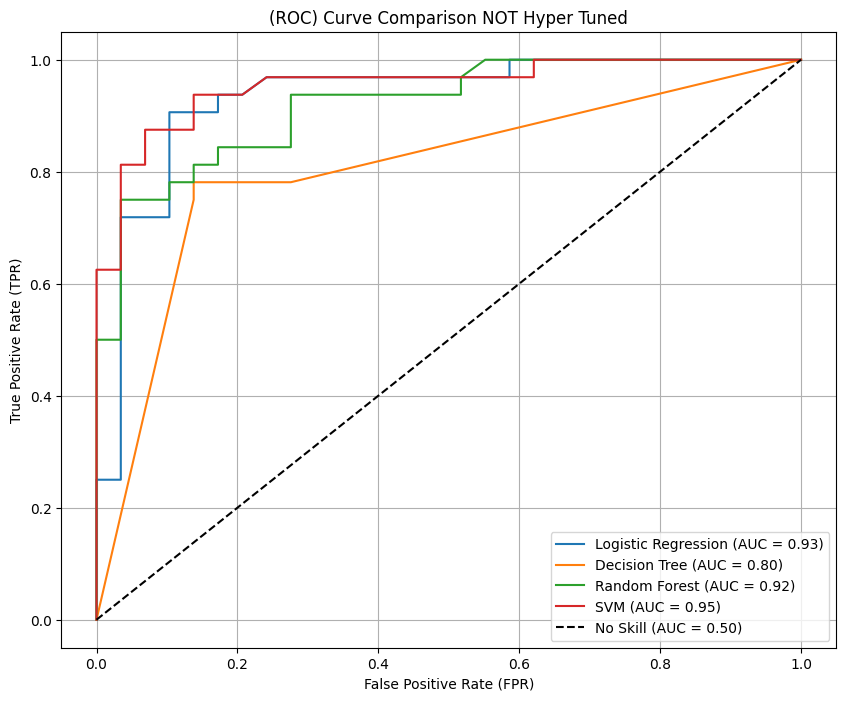

In [10]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

LR_probs = LR_model.predict_proba(X_test)[:, 1]
DT_probs = DT_model.predict_proba(X_test)[:, 1]
RF_probs = RF_model.predict_proba(X_test)[:, 1]
SVM_probs = SVM_model.predict_proba(X_test)[:, 1]


lr_fpr, lr_tpr, _ = roc_curve(y_test, LR_probs)
lr_auc = auc(lr_fpr, lr_tpr)

dt_fpr, dt_tpr, _ = roc_curve(y_test, DT_probs)
dt_auc = auc(dt_fpr, dt_tpr)

rf_fpr, rf_tpr, _ = roc_curve(y_test, RF_probs)
rf_auc = auc(rf_fpr, rf_tpr)

svm_fpr, svm_tpr, _ = roc_curve(y_test, SVM_probs)
svm_auc = auc(svm_fpr, svm_tpr)


plt.figure(figsize=(10, 8))

plt.plot(lr_fpr, lr_tpr, label=f'Logistic Regression (AUC = {lr_auc:.2f})')
plt.plot(dt_fpr, dt_tpr, label=f'Decision Tree (AUC = {dt_auc:.2f})')
plt.plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {rf_auc:.2f})')
plt.plot(svm_fpr, svm_tpr, label=f'SVM (AUC = {svm_auc:.2f})')


plt.plot([0, 1], [0, 1], 'k--', label='No Skill (AUC = 0.50)')

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('(ROC) Curve Comparison NOT Hyper Tuned')
plt.legend(loc='lower right')
plt.grid(True)

roc_plot_filepath = os.path.join('D:\\Heart_Disease_Project\\results', 'roc_curve_NOT_HyperTuned.png')
plt.savefig(roc_plot_filepath)
plt.show()



**Note on Curve Appearance:** The resulting ROC curves appear jagged rather than smooth. This is the expected behavior and a direct result of evaluating the models on a very small test set (n=61). A smaller sample size leads to a more discrete set of predicted probabilities, which in turn creates a step-like curve. The plots are a valid representation of model performance on this particular data.

#### **Conclusion** Although accuracy and F1-scores were nearly identical, the AUC score reveals that the **SVM (AUC=0.95) is the superior model**, demonstrating a better ability to distinguish between classes than Logistic Regression (AUC=0.93). <br>
#### I will make the final decision between them after hyperparameter tuning.

## Saving Logistic Regression and SVM models

In [9]:
import os
import pickle

directory_path = r'D:\Heart_Disease_Project\models'
filename = 'Logistic_Regression_model.pkl'

full_path = os.path.join(directory_path, filename)
os.makedirs(directory_path, exist_ok=True)

with open(full_path, 'wb') as file:
    pickle.dump(LR_model, file)

filename = 'SVM_model.pkl'
full_path = os.path.join(directory_path, filename)

with open(full_path, 'wb') as file:
    pickle.dump(SVM_model, file)
